In [1]:
### standard libraries
import time
import numpy as np
import matplotlib.pyplot as plt
import importlib

### other
import mrcfile

### my modules
from fast_volume_align_ot import utils, plots, transforms, signals, fle_3d, alignments, distances

### testing
from scipy.stats import norm
from scipy.special import erfinv

In [11]:
def compute_icdf(N, sigma):
    # Total mass (upper bound of y)
    ymax = 2 * np.pi * sigma * np.sqrt(2 * np.pi)
    # ymax = 1
    
    # Grid in y (avoid exact 0 and ymax to prevent ±inf)
    eps = 1e-12
    y = np.linspace(eps, ymax - eps, N)
    
    # Normalize to [0,1]
    u = y / ymax
    
    # ICDF (quantile function)
    s = norm.ppf(u)
    
    return y, s

    
def compute_icdf_erf(N, sigma):
    ymax = 2 * np.pi * sigma * np.sqrt(2 * np.pi)
    
    eps = 1e-12
    y = np.linspace(eps, ymax - eps, N)
    
    u = y / ymax
    s = np.sqrt(2) * erfinv(2 * u - 1)
    
    return y, s

In [3]:
importlib.reload(utils)
N = 65
d = 3
sigma = 5

f = utils.gaussian_3d(N, sigma=sigma)
g = utils.gaussian_3d(N, sigma=sigma)

f = signals.Signal(f, d=3, dx=1).preprocess_signals()[0] 
g = signals.Signal(g, d=3, dx=1).preprocess_signals()[0]

print(f.shape)

(65, 65, 65)


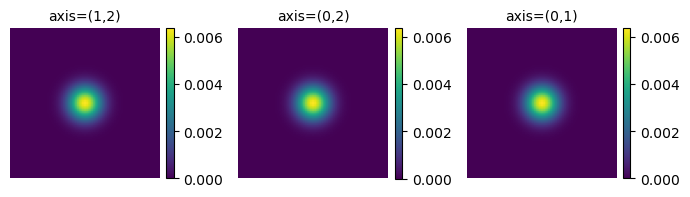

In [4]:
plots.orthogonal_2D_projection_plot(f)

In [5]:
### EV: Note setting normalize=False
###     this shouldn't matter for a centered Gaussian
###     but would matter for an asymmetric function

f_rt = transforms.Transform(f, d=3).radon_transform()[0]
f_cdf = transforms.Transform(f, d=3).cdf_transform(normalize=False)[0]
f_icdf = transforms.Transform(f, d=3).inverse_cdf_transform(normalize=False)[0]

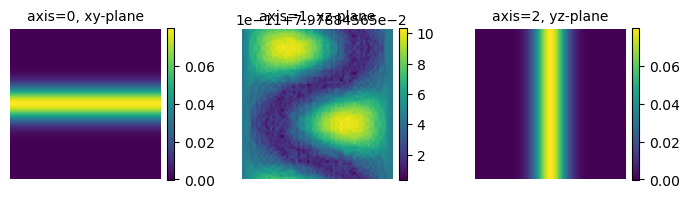

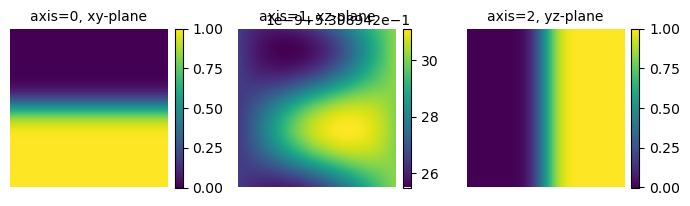

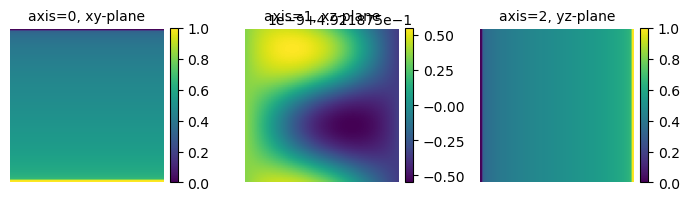

In [6]:
plots.orthogonal_2D_slice_plot(f_rt)
plots.orthogonal_2D_slice_plot(f_cdf)
plots.orthogonal_2D_slice_plot(f_icdf)

In [12]:
z1 = compute_icdf(N, sigma)

z2 = compute_icdf_erf(N, sigma)

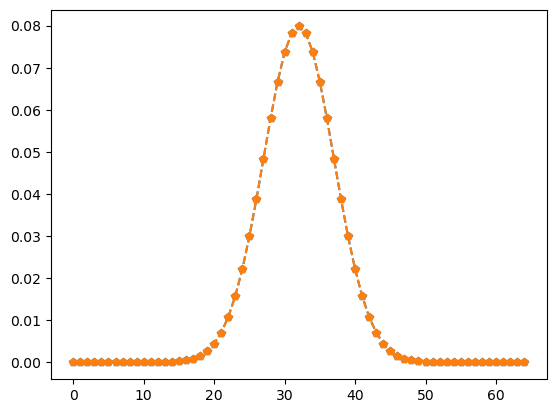

In [13]:
plt.plot(f_rt[0, :, 0], 'p--')
plt.plot(f_rt[36, :, 52], 'p--')

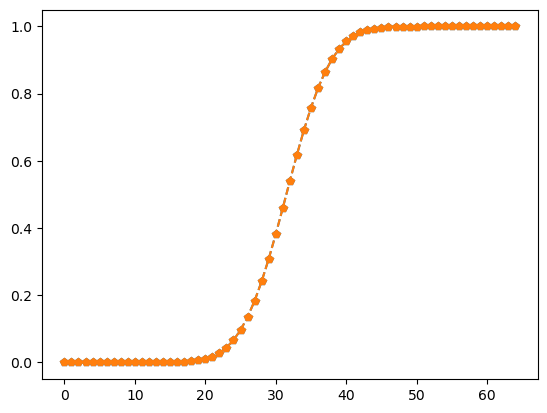

In [14]:
plt.plot(f_cdf[0, :, 0], 'p--')
plt.plot(f_cdf[36, :, 22], 'p--')

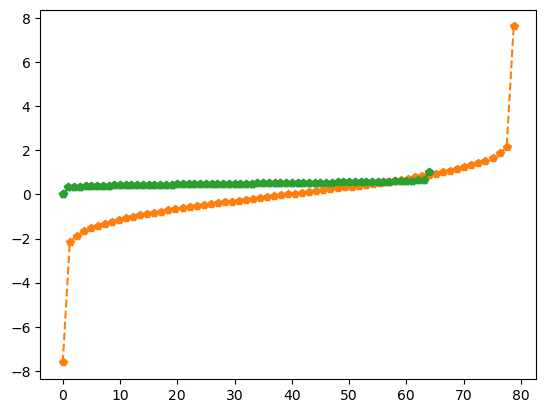

In [17]:
plt.plot(f_icdf[0, :, 0], 'p--')
plt.plot(f_icdf[36, :, 22], 'p--')

In [33]:
z = np.linspace(0,1,endpoint=False)
# cdf = 3/4*(t-1/3*t**3+2/3)
icdf = np.zeros(z.shape, dtype=np.float64)

for i in range(len(z)):
    p = np.poly1d([-1/4, 0, 3/4, 1/2-z[i]])
    tmp = np.roots(p)
    ind = np.argmin(np.imag(tmp))

    icdf[i] = tmp[ind]

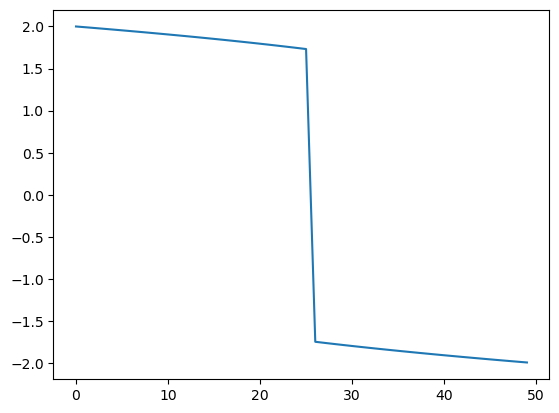

In [34]:
plt.plot(icdf)